In [1]:
%load_ext autoreload
%autoreload 2
import sys
if "../" not in sys.path:
    sys.path.append("../")

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

from scipy.special import roots_laguerre
from scipy.integrate import quad
from math import factorial

import signature.tensor_algebra as ta
from signature.ode_integration import *

PALETTE = ["#5C7B55", "#C0714A", "#C9A84C", "#A8C5A0", "#8B5A6B", "#4A5568"]
plt.rcParams["figure.figsize"]        = ((1 + np.sqrt(5)) / 2 * 5, 5)
plt.rcParams["figure.autolayout"]     = True
plt.rcParams["patch.force_edgecolor"] = False
plt.rcParams["axes.grid"]             = True
plt.rcParams['axes.prop_cycle']       = matplotlib.cycler(color=PALETTE)

## Signature stochastic control: recentered Riccati vs. Monte-Carlo (Section 5)

Two realizations of a signature-tracking control problem, comparing the Riccati feedback (with and without dynamic recentering) to a Monte-Carlo benchmark.

For a group-like $\mathbb{X}$, let $\psi^{\mathbb{X}}$ solve the signature Riccati equation on the tensor algebra (paper letters $0=$ time, $1=$ state; in the code these are letters $1$ and $2$)
$$
\dot\psi^{\mathbb{X}}_t + \psi^{\mathbb{X}}_t\big|_0 + \tfrac12\,\psi^{\mathbb{X}}_t\big|_{11} + \tfrac12\big(\psi^{\mathbb{X}}_t\big|_1\big)^{\text{ш} 2} = 0,
\qquad \psi^{\mathbb{X}}_T = {}_\mathbb{X}\,|\,p .
$$
On the interval starting at a recentering time $\sigma$ (with current state $\widehat{\mathbb{X}}^{\alpha^*}_\sigma$), the optimal value process and feedback control are
$$
V^*_t = \big\langle \psi^{\widehat{\mathbb{X}}^{\alpha^*}_\sigma}_t,\ \widehat{\mathbb{X}}^{\alpha^*}_{\sigma,t}\big\rangle,
\qquad
\alpha^*_t = \big\langle \psi^{\widehat{\mathbb{X}}^{\alpha^*}_\sigma}_t\big|_1,\ \widehat{\mathbb{X}}^{\alpha^*}_{\sigma,t}\big\rangle .
$$
This local expansion holds until the seminorm tracker leaves the convergence ball; we then recenter, at
$$
\tau_{n+1} = \inf\Big\{ t>\tau_n :\ \big\|\exp^{\text{ш}}\!\big(\overline{\psi^{\widehat{\mathbb{X}}^{\alpha^*}_{\tau_n}}_t}\big)\big\|_{\widehat{\mathbb{X}}^{\alpha^*}_{\tau_n,t}} \ge 2-\varepsilon \Big\},
\qquad \overline{\ell} := \ell - \ell^{\varnothing}\varnothing .
$$
The Monte-Carlo benchmark evaluates the same quantities as conditional expectations over the Brownian signature $\widehat{\mathbb{W}}_{t,T}$:
$$
v(t,\widehat{\mathbb{X}}_t) = \log \mathbb{E}\big[ e^{\langle p,\ \widehat{\mathbb{X}}_t \otimes \widehat{\mathbb{W}}_{t,T}\rangle} \big],
\qquad
\alpha^*(t,\widehat{\mathbb{X}}_t) = \frac{\mathbb{E}\big[ e^{\langle p,\ \widehat{\mathbb{X}}_t \otimes \widehat{\mathbb{W}}_{t,T}\rangle}\,\langle p,\ \widehat{\mathbb{X}}_t \otimes \mathbf{1} \otimes \widehat{\mathbb{W}}_{t,T}\rangle \big]}{\mathbb{E}\big[ e^{\langle p,\ \widehat{\mathbb{X}}_t \otimes \widehat{\mathbb{W}}_{t,T}\rangle} \big]} .
$$
The shared problem data and a plotting helper are defined once below; each example then only specifies its running cost.

In [7]:
# ============================ shared setup (Section 5.1) ============================
from signature import sig_control as sc
import iisignature

dim, trunc = 2, 10                 # time-augmented signature: letter 1 = time, 2 = state
T, mu      = 0.4, 1.4              # horizon and target level
w_q, w_r   = 5.0, 5.0             # running (quartic) and terminal (signature-matching) weights
n_dw, size = 300, 12              # time steps and number of Brownian paths
M_sig, eps = 2, 0.01             # signature-matching order; recentering tolerance (recenter at tracker >= 1 - eps/2)
t_grid     = np.linspace(0.0, T, n_dw)
step_fun   = step_fun_pece

stab                  = ta.get_shuffle_table(table_trunc=trunc, dim=dim)
e_state, e_time, unit = ta.from_word(2, trunc, dim), ta.from_word(1, trunc, dim), ta.unit(trunc, dim)

# Riccati generator  R psi = psi|_1 + 1/2 psi|_22 + 1/2 (psi|_2)^{sh 2}
@jax.jit
def ode_fun(psi, args):
    return psi.proj(1) + psi.proj(22) * 0.5 + ta.shuffle_pow(psi.proj(2), 2, args["shuffle_table"]) * 0.5

# terminal signature-matching reward  r = -w_r * sum_{|v|<=2, v contains the state letter} (v - Y_T^v)^{sh 2},
# matching the order-<=2 signature of the ramp-and-hold target  Y(t) = mu * (2t/T ^ 1).
Y = lambda c: mu * np.clip(2.0 * c / T, 0.0, 1.0)
Sig_star = ta.path_to_signature(jnp.asarray(np.column_stack([t_grid, Y(t_grid)])), trunc, only_terminal_sig=True)
r = ta.zero(trunc, dim)
for idx in range(1, ta.number_of_words_up_to_trunc(dim=dim, trunc=M_sig)):
    word = int(ta.index_to_word(idx, dim))
    if "2" in str(word):
        v = ta.from_word(word, trunc, dim)
        r = r + ta.shuffle_pow(v, 2, stab) - v * (2.0 * float(Sig_star.array[idx]))
r = r * (-w_r)

# common Brownian increments used by both examples
rng = np.random.default_rng(42)
W = np.zeros((size, n_dw)); W[:, 1:] = np.cumsum(rng.normal(size=(size, n_dw - 1)) * np.sqrt(T / (n_dw - 1)), axis=1)
dW = np.diff(W, axis=1)

# 2x2 figure: [[state, control], [seminorm tracker, value]] for the chosen trajectories.
# `runs` maps label -> (ControlResult, line-style); `target_lines` is a list of (y, style, label).
SOLID, DASH, MARK = dict(ls="-", lw=1.2), dict(ls="--", lw=1.2), dict(ls="none", marker="o", ms=4, markevery=10)
_PAL = ["#C0714A", "#5C7B55", "#8B5A6B"]
def plot_solution(runs, show, target_lines, savepath):
    fig, ax = plt.subplots(2, 2, figsize=(13, 9)); ax = ax.ravel()
    for j, k in enumerate(show):
        for _, (run, s) in runs.items():
            ax[0].plot(t_grid,      run.X[k],             color=_PAL[j], **s)
            ax[1].plot(t_grid[:-1], run.control[k, :-1],  color=_PAL[j], **s)
            ax[3].plot(t_grid[:-1], run.value[k, :-1],    color=_PAL[j], **s)
            if "norm_tracker" in run.extra:
                ax[2].plot(t_grid[:-1], run.extra["norm_tracker"][k, :-1], color=_PAL[j], **s)
    ax[2].axhline(1.0, color="r", ls=":", lw=1); ax[2].set_ylim(0, 2)
    for name, (_, s) in runs.items():
        ax[0].plot([], [], color="k", label=name, **s)
    for y, s, lab in target_lines:
        ax[0].plot(t_grid, y, label=lab, **s)
    ax[0].legend(loc="best")
    ax[0].set_title(r"State $X^{\alpha^*}_t$");  ax[1].set_title(r"Control $\alpha_t^*$")
    ax[2].set_title(r"Seminorm tracker $\|\exp(\overline{\chi}_t^{\widehat{\mathbb{X}}_{\tau}^{\alpha^*}})\|_{\widehat{\mathbb{X}}_{\tau, t}^{\alpha^*}} \,/\, 2$")
    ax[3].set_title(r"Value process $V_t^*$")
    for a in ax: a.set_xlabel("t")
    fig.tight_layout(); fig.savefig(savepath, format="pdf", transparent=True)

def report(runs, show):
    mc = runs["Monte Carlo"][0]
    for name, (run, _) in runs.items():
        err = np.nanmax(np.abs(run.control[show][:, :-1] - mc.control[show][:, :-1]))
        print(f"{name:26s} max|alpha - alpha_MC| on shown paths = {err:.3f}")

### Example 1 — fixed target $\mu$

We maximize
$$
J(\alpha) = -\tfrac12\!\int_0^T\!\alpha_t^2\,dt \;-\; w_q\!\int_0^T\!(X^\alpha_t-\mu)^4\,dt \;-\; w_r\!\!\sum_{|v|\le 2}\big(\widehat{\mathbb{X}}^{\alpha,v}_T-\widehat{\mathbb{Y}}^{\,v}_T\big)^2 ,
$$
a quartic running cost plus a terminal matching the order-$\le 2$ signature of the ramp-and-hold target $Y(t)=\mu\,(2t/T\wedge 1)$. Split into running and terminal coefficients,
$$
q = -w_q\,(\mathbf{1}-\mu\varnothing)^{\text{ш} 4},
\qquad
r = -w_r\!\!\sum_{|v|\le 2}\big(v-\widehat{\mathbb{Y}}^{\,v}_T\big)^{\text{ш} 2},
$$
with $\psi^{\mathbb{X}} = \chi^{\mathbb{X}} + \mathbb{X}\,|\,(q\mathbf{0})$. Since $\mu$ is constant, the running cost is folded into the terminal through the time letter and solved with `source=None`. Parameters: $\mu=1.4$, $w_q=w_r=5$, $T=0.4$, truncation $10$, $n_t=300$; Monte-Carlo with $5\cdot10^5$ Brownian-signature samples.

Riccati (no recentering)   max|alpha - alpha_MC| on shown paths = 36.521
Riccati (recentering)      max|alpha - alpha_MC| on shown paths = 0.156
Monte Carlo                max|alpha - alpha_MC| on shown paths = 0.000


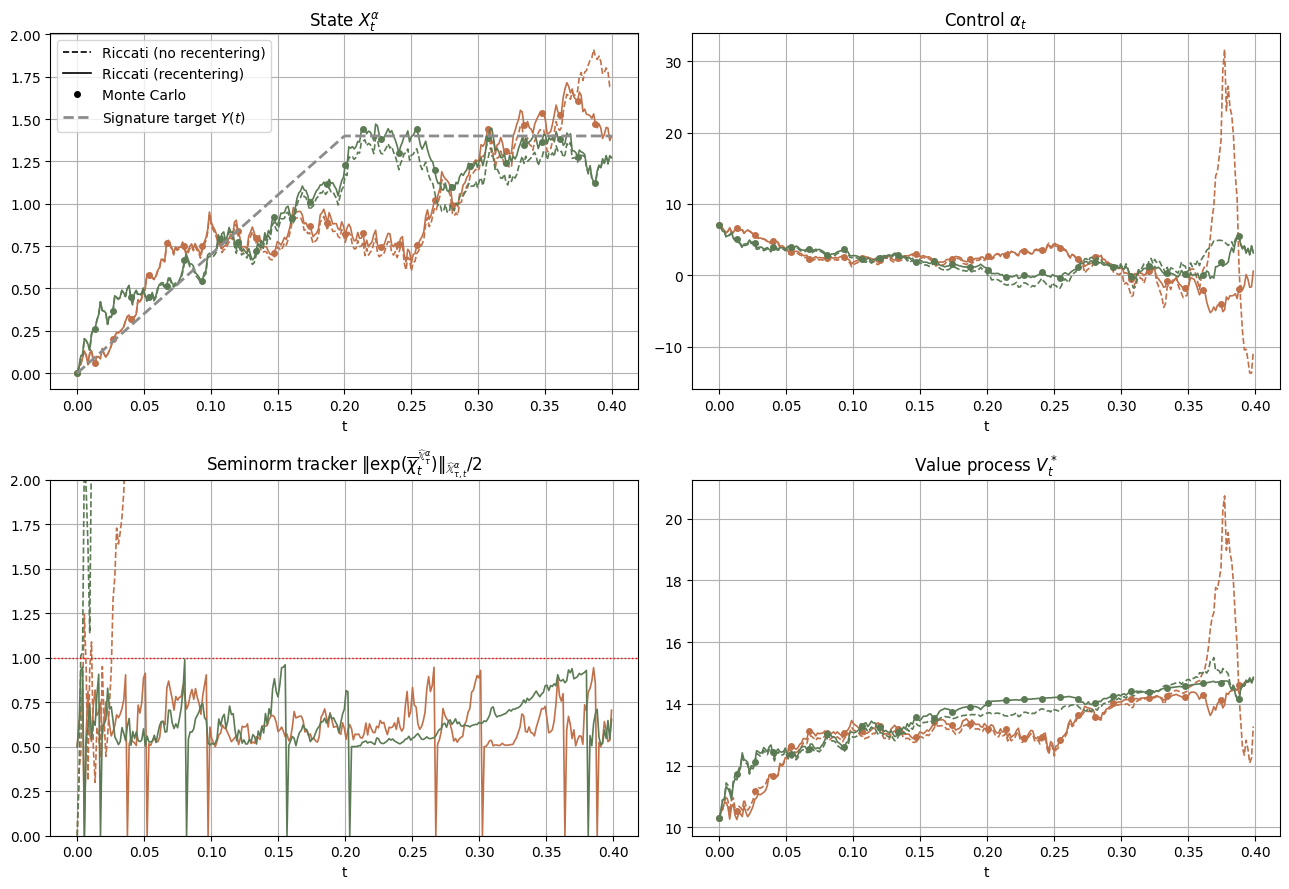

In [ ]:
# ===== Example 1: constant target mu  --  running cost -w_q (X - mu)^4 folded into the terminal =====
q = ta.shuffle_pow(e_state - unit * mu, 4, stab) * (-w_q)              # -w_q (X - mu)^4,  X = <2, Sig>
p = ta.tensor_prod(q, e_time) + r                                     # fold running cost via time letter + terminal r
psi = ode_solver_traj(fun=ode_fun, step_fun=step_fun, t_grid=t_grid,
                      init=p, args={"shuffle_table": stab, "source": None})

# truncation-exact Monte-Carlo sample: time-augmented Brownian signature up to deg(p)
p_deg = int(p.get_lengths_array()[np.abs(np.array(p.array)) > 1e-12].max())
N_MC, n_fine = 500_000, 80
rng_mc = np.random.default_rng(1); u = np.linspace(0.0, 1.0, n_fine)
W1 = np.cumsum(rng_mc.normal(size=(N_MC, n_fine - 1)) * np.sqrt(1.0 / (n_fine - 1)), axis=1)
paths = np.zeros((N_MC, n_fine, dim)); paths[:, 1:, 0] = u[1:][None, :]; paths[:, 1:, 1] = W1
SigW1 = ta.from_array(jnp.asarray(np.vstack([np.ones((1, N_MC)), iisignature.sig(paths, p_deg).T])), trunc=p_deg, dim=dim)

rd = dict(ode_fun=ode_fun, step_fun=step_fun, t_grid=t_grid, r=p, shuffle_table=stab, source=None, state_letter=2)
runs = {
    "Riccati (no recentering)": (sc.simulate(dW, t_grid, sc.riccati_policy(psi, state_letter=2), trunc, dim), DASH),
    "Riccati (recentering)":    (sc.simulate_with_recentering(dW, t_grid, rd, trunc, dim=dim, recenter_threshold=1 - eps / 2), SOLID),
    "Monte Carlo":              (sc.simulate(dW, t_grid, sc.monte_carlo_policy(p, SigW1, T, trunc, dim), trunc, dim), MARK),
}
report(runs, show=[7, 10])
plot_solution(runs, show=[7, 10],
              target_lines=[(Y(t_grid), dict(ls="--", color="0.55", lw=2), r"Signature target $Y(t)$")],
              savepath="images/sig-control/example_mu_const.pdf")

### Example 2 — time-dependent target $\mu(t)=2\sqrt t$

Same problem, but the running-cost target is now **time-dependent**, giving the time-dependent source
$$
q_t = -w_q\,(\mathbf{1}-\mu(t)\varnothing)^{\text{ш} 4},\qquad \mu(t)=2\sqrt t .
$$
This cannot be folded into the terminal, so $\chi^{\mathbb{X}}$ solves the Riccati equation with a time-dependent source
$$
\dot\chi^{\mathbb{X}}_t + \mathcal{R}\,\chi^{\mathbb{X}}_t + {}_\mathbb{X}\,|\,q_t = 0,
\qquad \chi^{\mathbb{X}}_T = {}_\mathbb{X}\,|\,r,
\qquad
\mathcal{R}\ell = \ell\big|_0 + \tfrac12\ell\big|_{11} + \tfrac12\big(\ell\big|_1\big)^{\text{ш} 2},
$$
and recentering shifts the terminal $r$ **and** every time-slice of $q_t$ by the running signature $\mathbb{X}$. The signature-matching terminal $r$ (targeting $Y$) is unchanged.

Riccati (recentering)      max|alpha - alpha_MC| on shown paths = 0.323
Riccati (no recentering)   max|alpha - alpha_MC| on shown paths = 21.296
Monte Carlo                max|alpha - alpha_MC| on shown paths = 0.000


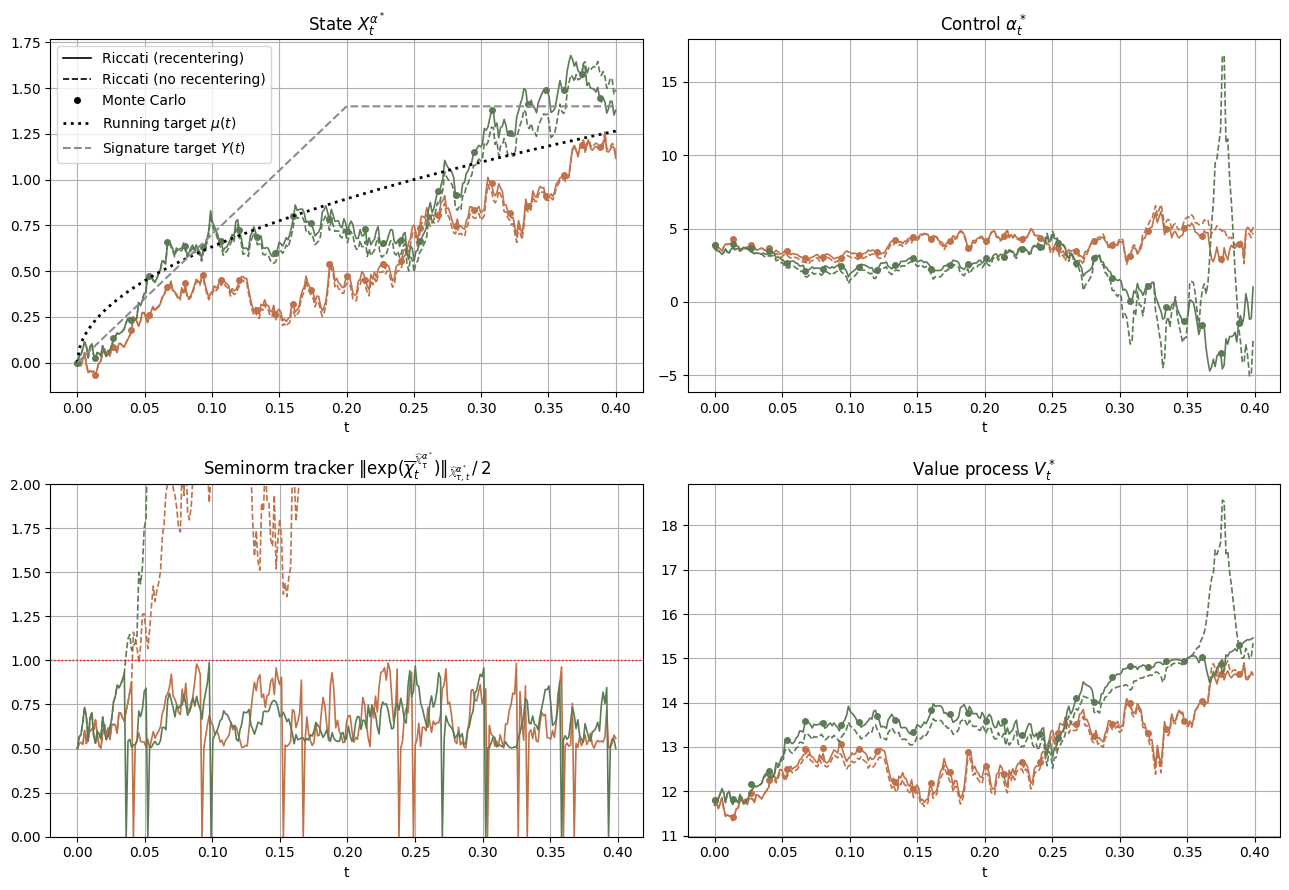

In [9]:
# ===== Example 2: time-dependent target mu(t) = 2 sqrt(t)  --  time-dependent running-cost source =====
mu_t = lambda c: 2.0 * np.sqrt(np.clip(c, 0.0, None))
stab_q, e_state_q, unit_q = ta.get_shuffle_table(table_trunc=4, dim=dim), ta.from_word(2, 4, dim), ta.unit(4, dim)
# source column i = q at reversed-time step i (calendar T - t_grid[i]); kept at truncation 4 = deg(q)
q_traj = ta.from_array(jnp.stack([(ta.shuffle_pow(e_state_q - unit_q * mu_t(T - t_grid[i]), 4, stab_q) * (-w_q)).array
                                  for i in range(n_dw)], axis=1), 4, dim)
rd = dict(ode_fun=ode_fun, step_fun=step_fun, t_grid=t_grid, r=r, shuffle_table=stab, source=q_traj, state_letter=2)

# Monte-Carlo benchmark for a time-dependent running cost
deg  = max(sc._max_degree(r), sc._max_degree(q_traj))
traj = sc.brownian_signature_trajectory(t_grid, N_MC=50_000, trunc_mc=deg, dim=dim, seed=7)
runs = {
    "Riccati (recentering)":    (sc.simulate_with_recentering(dW, t_grid, rd, trunc, dim=dim, recenter_threshold=1 - eps / 2), SOLID),
    "Riccati (no recentering)": (sc.simulate_with_recentering(dW, t_grid, rd, trunc, dim=dim, recenter_threshold=np.inf), DASH),
    "Monte Carlo":              (sc.simulate(dW, t_grid, sc.monte_carlo_source_policy(r, q_traj, traj, t_grid, dim=dim), trunc, dim), MARK),
}
report(runs, show=[0, 7])
plot_solution(runs, show=[0, 7],
              target_lines=[(mu_t(t_grid), dict(ls=":", color="k", lw=2), r"Running target $\mu(t)$"),
                            (Y(t_grid),   dict(ls="--", color="0.55", lw=1.5), r"Signature target $Y(t)$")],
              savepath="images/sig-control/example_mu_timedep.pdf")